In [1]:
import pandas as pd
import seaborn as sns
import os
import certifi
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt


In [ ]:
os.environ["SSL_CERT_FILE"] = certifi.where()

telco = fetch_openml(data_id=45568, as_frame=True)
df_churn = telco.frame

print(df_churn.shape)

(7043, 20)


In [3]:
display(df_churn.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   gender            7043 non-null   category
 1   SeniorCitizen     7043 non-null   category
 2   Partner           7043 non-null   category
 3   Dependents        7043 non-null   category
 4   tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   category
 6   MultipleLines     7043 non-null   category
 7   InternetService   7043 non-null   category
 8   OnlineSecurity    7043 non-null   category
 9   OnlineBackup      7043 non-null   category
 10  DeviceProtection  7043 non-null   category
 11  TechSupport       7043 non-null   category
 12  StreamingTV       7043 non-null   category
 13  StreamingMovies   7043 non-null   category
 14  Contract          7043 non-null   category
 15  PaperlessBilling  7043 non-null   category
 16  PaymentMethod     7043 non-null   c

In [5]:
df_churn.describe(include='all')

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7032.000000,7043
unique,2,2,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,Male,0,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,3555,5901,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2283.300441,NaN
std,NaN,NaN,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.771362,NaN
min,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,401.450000,NaN
50%,NaN,NaN,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN


In [6]:
df_churn['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [7]:
print(f"Duplicates: {df_churn.duplicated().sum()}")

Duplicates: 22


Text(0.5, 1.0, 'Distribution of Churn')

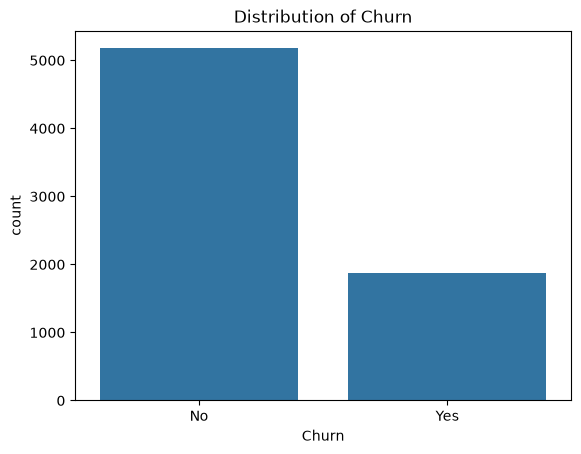

In [8]:
y_barchart = sns.countplot(data = df_churn, x = 'Churn', stat = 'count')
y_barchart.set_title("Distribution of Churn")

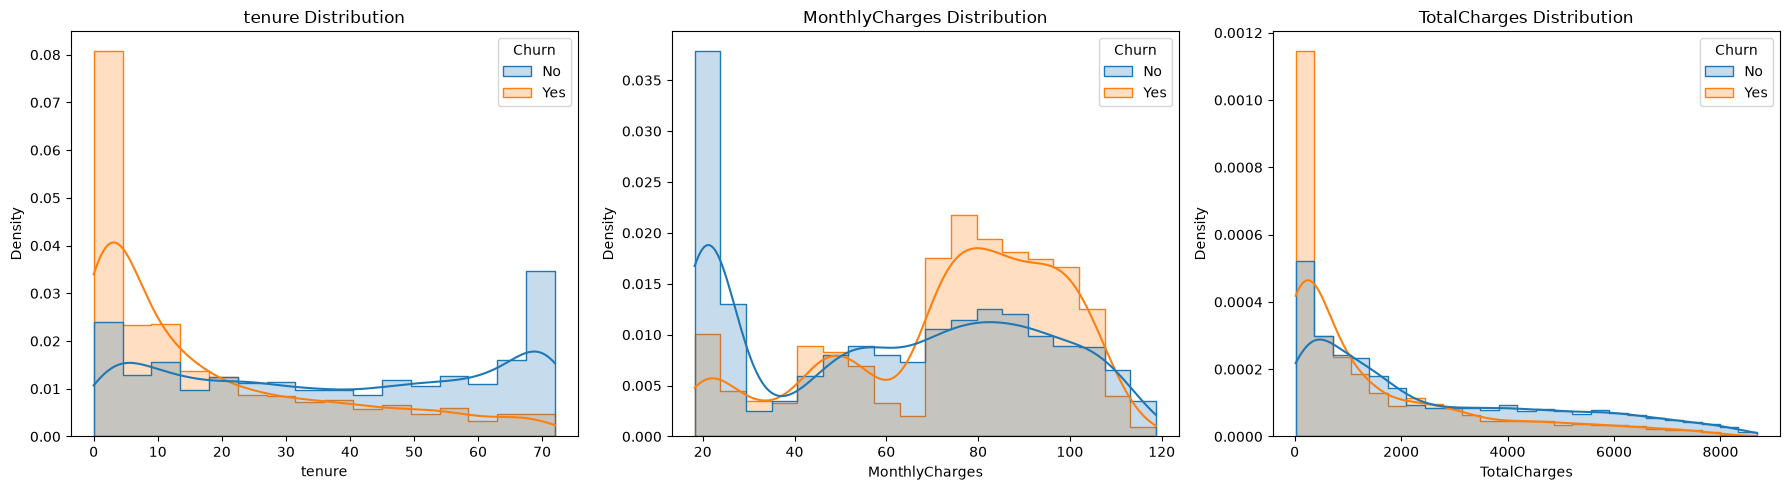

In [9]:

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, numeric_cols):
    sns.histplot(data=df_churn, x=column, hue='Churn', kde=True,
                 element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(f'{column} Distribution')

plt.tight_layout()
plt.show()

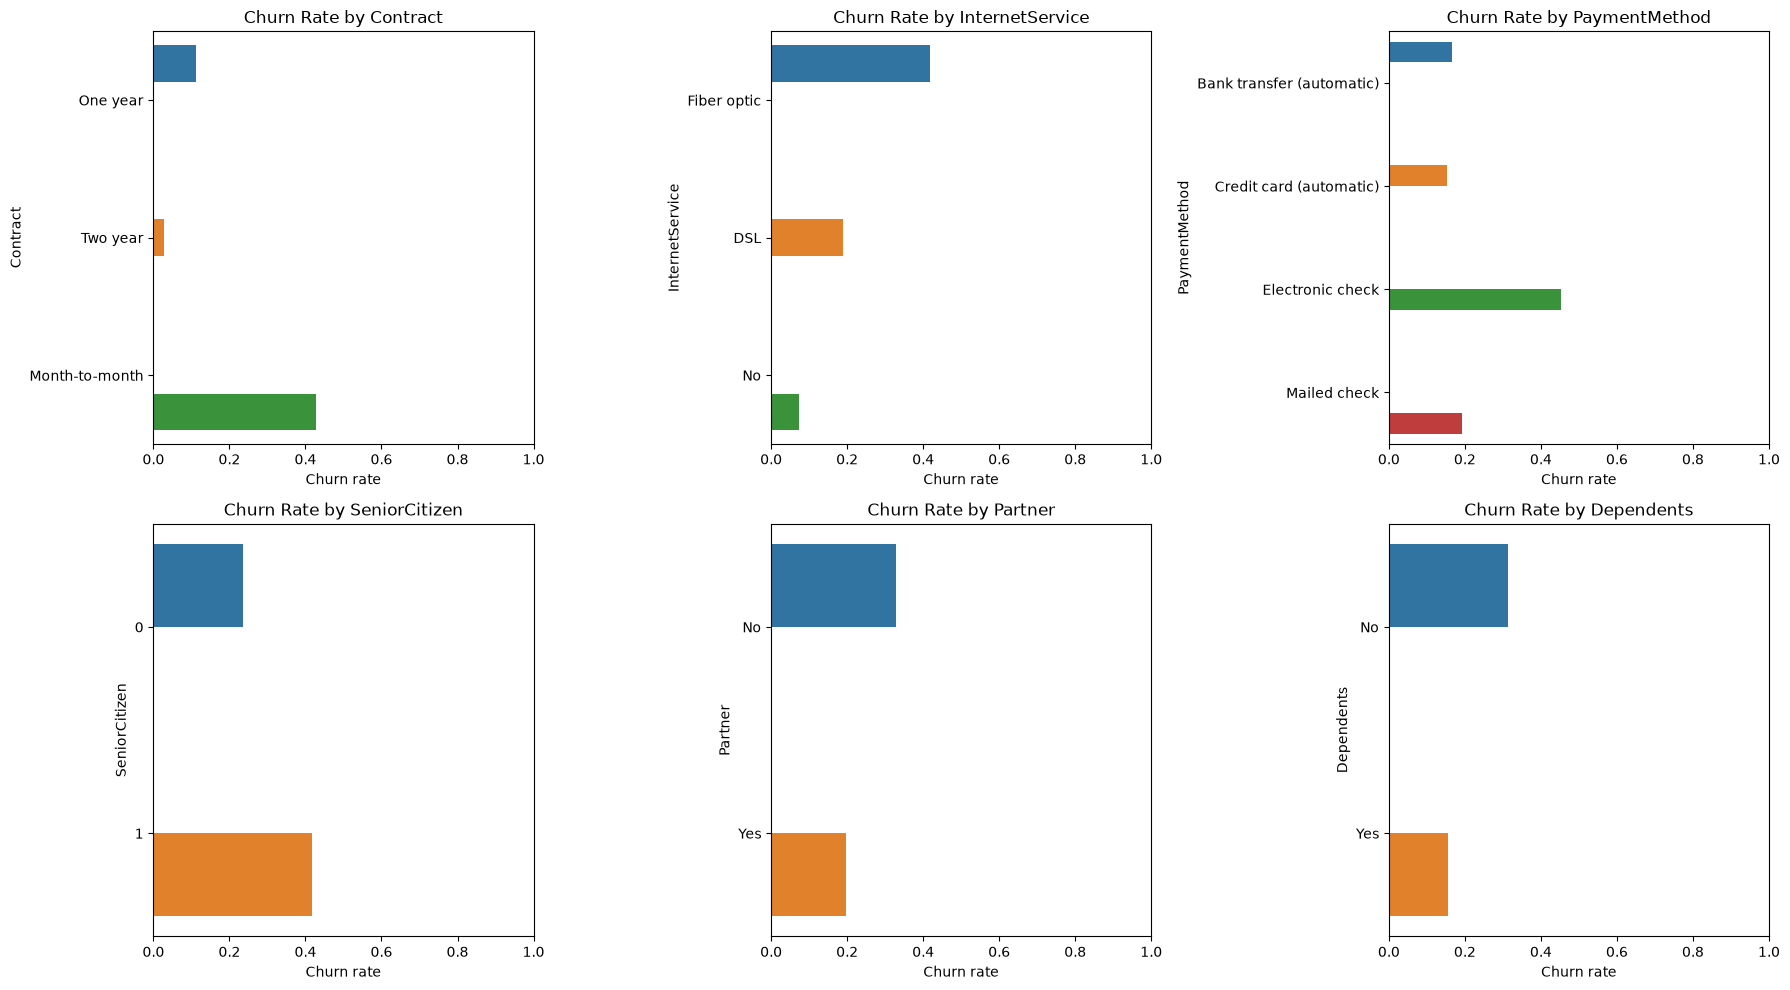

In [10]:
categorical_cols = ['Contract', 'InternetService', 'PaymentMethod',
                    'SeniorCitizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, column in zip(axes.flat, categorical_cols):
    churn_rate = (
        df_churn.groupby(column, observed=False)['Churn']
        .apply(lambda values: (values == 'Yes').mean())
        .reset_index(name='ChurnRate')
    )
    sns.barplot(data=churn_rate, x='ChurnRate', y=column,
                hue=column, legend=False, ax=ax)
    ax.set_title(f'Churn Rate by {column}')
    ax.set_xlabel('Churn rate')
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

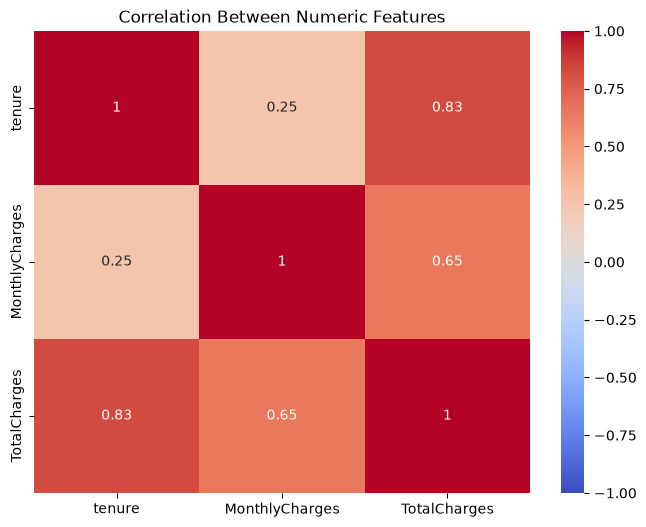

In [11]:
plt.figure(figsize=(8, 6))
correlation = df_churn[numeric_cols].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Features')
plt.show()

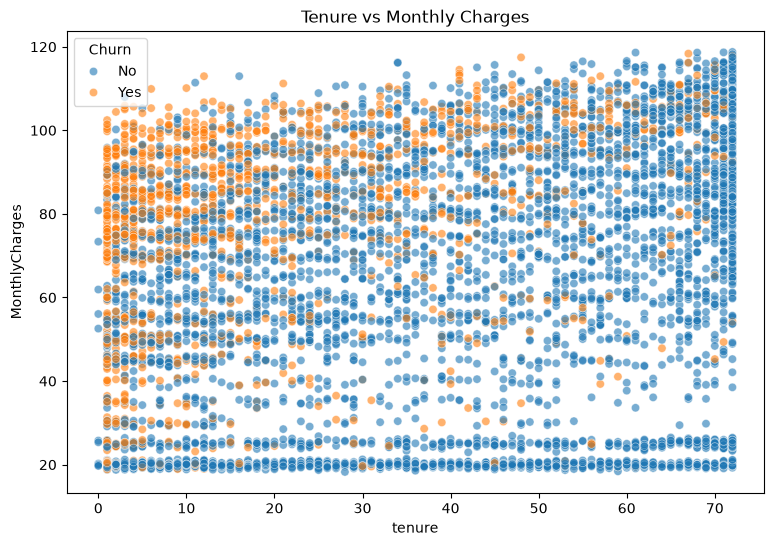

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_churn,
    x='tenure',
    y='MonthlyCharges',
    hue='Churn',
    alpha=0.6
)
plt.title('Tenure vs Monthly Charges')
plt.show()